# Figure 6 — Tissue-enriched proteins across wild-type (Canton-S) development

**Run order:** fig2 → fig3 → fig5 → **fig6**. Needs `outputs/intermediate/larva_tissue_enriched_proteins.csv` (fig5)
and `outputs/intermediate/mf_timecourse_clusters.csv` (fig3).

| Output | What | File (in `outputs/`) |
|---|---|---|
| **Fig 6B** | K-means (k = 6) heatmap of the whole time course; tissue-enriched / all proteins per cluster | `fig6/fig6B_kmeans_heatmap` |
| **Fig 6C** | Developmental onset of tissue-enriched proteins | `fig6/fig6C_onset_bar` |
| **Fig 6D** | Brain-enriched proteins, shared clusters (k = 6, fit on all tissue-enriched proteins) | `fig6/fig6D_brain_clusters` |
| **Fig 6E** | Tissue-enriched proteins in MF time-course clusters 8, 9, 6, 3 | `fig6/fig6E_tissue_composition_mf_clusters` |
| **Fig S5** | Same shared clusters as 6D, one panel per tissue | `fig6/figS5_shared_clusters_by_tissue` |
| **Fig S4** | Ten FlyBase gene groups across development | `fig6/figS4_gene_group_violins` |
| **Supplementary Table S7** | Whole time course with k-means cluster and tissue of enrichment | `supplementary_tables/Table_S7_CanS_timecourse.csv` |
| **Supplementary Table S8** | Tissue-enriched proteins detected in the time course, with shared cluster | `supplementary_tables/Table_S8_CanS_tissue_enriched.csv` |

Fig 6A is a schematic (not produced here).

**Inputs:** `raw data/protein_quant_2242_cns21_devseries.tsv`, `helper files/genetable.xlsx`, `helper files/gene_group_data_fb_2025_05.tsv.gz`, plus the two
intermediate files above.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.axes_grid1 import make_axes_locatable
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

import common as cm
from common import TISSUE_COLORS_DARK

OUT = cm.fig_dir('fig6')
QUANT_FILE    = cm.DATA_DIR / 'protein_quant_2242_cns21_devseries.tsv'
ENRICHED_FILE = cm.INTERMEDIATE_DIR / 'larva_tissue_enriched_proteins.csv'
MF_CLUSTERS   = cm.INTERMEDIATE_DIR / 'mf_timecourse_clusters.csv'
cm.require(QUANT_FILE, cm.GENETABLE, cm.GENE_GROUP_FILE, ENRICHED_FILE, MF_CLUSTERS)

## Load and normalise the time course (18 channels)

In [2]:
all_channels = ['126_sn', '127n_sn', '127c_sn', '128n_sn',
                '128c_sn', '129n_sn', '129c_sn', '130n_sn',
                '130c_sn', '131n_sn', '131c_sn', '132n_sn',
                '132c_sn', '133n_sn', '133c_sn', '134n_sn',
                '134c_sn', '135n_sn']
experiment_channels = ['Cans0to1', 'Cans1to2', 'Cans2to3', 'Cans3to4',
                       'Cans4to5', 'Cans5to6', 'Cans6to7', 'Cans7to8',
                       'Cans8to9', 'Cans9to11', 'Cans11to13', 'Cans13to15',
                       'Cans15to17', 'Cans17to19', 'Cans19to23', 'CansL1',
                       'CansL2', 'CansL3']
result = cm.normalize_tmt(QUANT_FILE, all_channels, experiment_channels, min_sumSN=360)
channel_columns = [f'{ch}_norm' for ch in experiment_channels]
result[channel_columns] = result[channel_columns].apply(pd.to_numeric, errors='coerce')

protein_quant_2242_cns21_devseries.tsv: 8354 rows -> 8090 pass S/N + decoy filter -> 8061 with gene annotation


## K-means of the whole time course (k = 6) and the larval tissue-enriched proteins
K-means on standardised profiles of all proteins with complete data; labels 1–6.
`result_shared` = time-course proteins that are tissue-enriched in the larva (fig5), tagged with their tissue.

In [3]:
K = 6
X = result[channel_columns].dropna()
km = KMeans(n_clusters=K, random_state=42, n_init=10)
result.loc[X.index, 'cluster'] = km.fit_predict(StandardScaler().fit_transform(X)) + 1
result['cluster'] = result['cluster'].astype('Int64')
print(result['cluster'].value_counts().sort_index().to_string())

tissue_excl = pd.read_csv(ENRICHED_FILE)
excl_map = (tissue_excl[['ProteinId', 'exclusive_to']].dropna(subset=['ProteinId'])
            .drop_duplicates(subset=['ProteinId']).set_index('ProteinId')['exclusive_to']
            .str.strip().str.lower())
result_shared = result[result['ProteinId'].isin(excl_map.index)].copy()
result_shared['tissue'] = result_shared['ProteinId'].map(excl_map)
print(f"\nTissue-enriched (larva): {excl_map.index.nunique()} | detected in time course: "
      f"{result_shared['ProteinId'].nunique()}")
print(result_shared['tissue'].value_counts().to_string())

cluster
1    1915
2     886
3    3813
4     812
5     400
6     235

Tissue-enriched (larva): 798 | detected in time course: 436
tissue
brain    161
gut      161
mt        93
discs     21


## Fig 6B — whole-dataset heatmap
Rows = proteins grouped by cluster (order C6, C3, C1, C5, C4, C2), within a cluster ordered by peak stage.
Left: cluster label and tissue-enriched / all proteins in the cluster.

Saved fig6/fig6B_kmeans_heatmap.pdf / .png


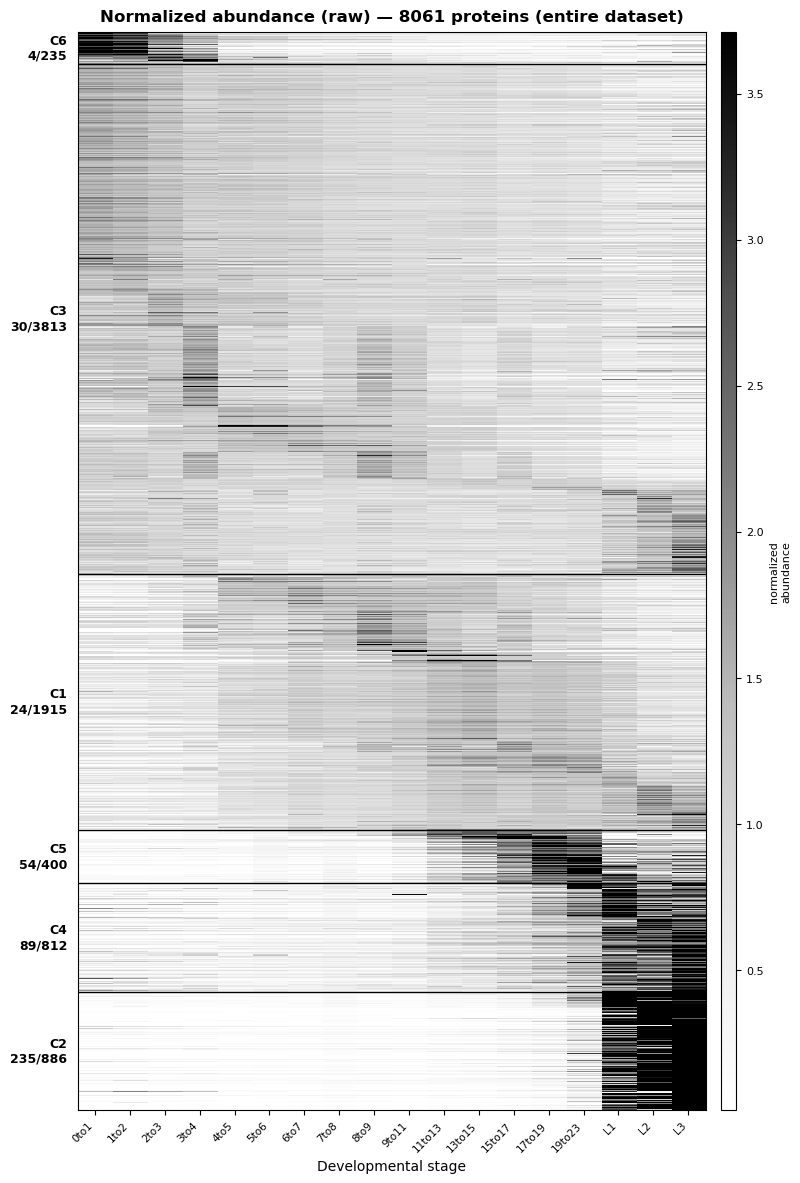

In [4]:
CLUSTER_ORDER = [6, 3, 1, 5, 4, 2]

data = result[result['cluster'].notna()].copy()
Xh = data[channel_columns]
enriched_ids = set(result_shared['ProteinId'])
meta = pd.DataFrame({'cluster':  data['cluster'].astype(int).values,
                     'enriched': data['ProteinId'].isin(enriched_ids).values,
                     'peak':     np.nan_to_num(Xh.values, nan=-np.inf).argmax(axis=1)}, index=data.index)
meta['rank'] = meta['cluster'].map({c: i for i, c in enumerate(CLUSTER_ORDER)})
row_order    = meta.sort_values(['rank', 'peak']).index
Mo           = Xh.loc[row_order].values
cluster_vec  = meta.loc[row_order, 'cluster'].values
enriched_vec = meta.loc[row_order, 'enriched'].values
n = Mo.shape[0]

vmin, vmax = np.nanpercentile(Xh.values, [2, 98])
fig, ax = plt.subplots(figsize=(8.5, float(np.clip(n * 0.02, 8, 14))))
cmap = plt.get_cmap('Greys').copy()
cmap.set_bad('#f2c4c4')
im = ax.imshow(np.ma.masked_invalid(Mo), aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax,
               interpolation='nearest', rasterized=True)

for b in np.where(np.diff(cluster_vec) != 0)[0] + 0.5:
    ax.axhline(b, color='black', lw=1.0)
starts = np.r_[0, np.where(np.diff(cluster_vec) != 0)[0] + 1, n]
for s, e in zip(starts[:-1], starts[1:]):
    ax.text(-0.8, (s + e - 1) / 2, f'C{cluster_vec[s]}\n{int(enriched_vec[s:e].sum())}/{e - s}',
            ha='right', va='center', fontsize=9, fontweight='bold', clip_on=False)

ax.set_yticks([])
ax.set_xticks(range(len(channel_columns)))
ax.set_xticklabels([c.replace('_norm', '').replace('Cans', '') for c in channel_columns],
                   rotation=45, ha='right', fontsize=7.5)
ax.set_xlabel('Developmental stage', fontsize=10)
ax.set_title(f'Normalized abundance (raw) — {n} proteins (entire dataset)', fontsize=12, fontweight='bold', pad=8)
cax = make_axes_locatable(ax).append_axes('right', size='2.5%', pad=0.15)
cb = fig.colorbar(im, cax=cax)
cb.set_label('normalized\nabundance', fontsize=8)
cb.ax.tick_params(labelsize=8)
cm.save_fig(fig, OUT, 'fig6B_kmeans_heatmap')
plt.show()

## Fig 6C — developmental onset of tissue-enriched proteins
Share of the tissue-enriched proteins (with a cluster) in each temporal category.

  Maternal        n=   4/436  (0.9%)
  Constant        n=  54/436  (12.4%)
  Late embryonic  n= 143/436  (32.8%)
  Larval only     n= 235/436  (53.9%)


Saved fig6/fig6C_onset_bar.pdf / .png


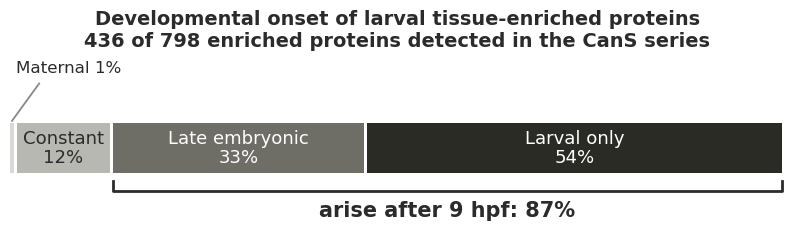

In [5]:
CATEGORIES = [                       # (label, clusters, fill, text colour)
    ('Maternal',       [6],    '#d9d9d5', '#2b2b2b'),
    ('Constant',       [1, 3], '#b8b8b2', '#2b2b2b'),
    ('Late embryonic', [5, 4], '#6e6e66', 'white'),
    ('Larval only',    [2],    '#2b2b26', 'white'),
]
BRACKET_CATS, BRACKET_TEXT = ['Late embryonic', 'Larval only'], 'arise after 9 hpf'
SMALL_PCT, GAP = 5, 0.4              # segments < SMALL_PCT % labelled above; white gap between segments (%)

cl = result.loc[result['ProteinId'].isin(enriched_ids) & result['cluster'].notna(), 'cluster'].astype(int)
total = len(cl)
rows = [dict(label=lab, n=int(cl.isin(cs).sum()), pct=100 * cl.isin(cs).sum() / total, fill=f, txt=tc)
        for lab, cs, f, tc in CATEGORIES]
for r in rows:
    print(f"  {r['label']:15s} n={r['n']:4d}/{total}  ({r['pct']:.1f}%)")

fig, ax = plt.subplots(figsize=(10, 2.2))
x, spans = 0.0, {}
for r in rows:
    w = r['pct']
    ax.add_patch(mpatches.Rectangle((x, 0), max(w - GAP, 0.15), 1, facecolor=r['fill'], edgecolor='none'))
    cx = x + (w - GAP) / 2
    if w >= SMALL_PCT:
        ax.text(cx, 0.5, f"{r['label']}\n{r['pct']:.0f}%", ha='center', va='center', fontsize=13,
                color=r['txt'], linespacing=1.1)
    else:
        ax.plot([cx, cx + 3.5], [1.05, 1.8], color='#888888', lw=1.3, clip_on=False)
        ax.text(cx + 0.5, 1.95, f"{r['label']} {r['pct']:.0f}%", ha='left', va='bottom', fontsize=12, color='#2b2b2b')
    spans[r['label']] = (x, x + w - GAP)
    x += w

bx0 = min(spans[c][0] for c in BRACKET_CATS)
bx1 = max(spans[c][1] for c in BRACKET_CATS)
b_pct = sum(r['pct'] for r in rows if r['label'] in BRACKET_CATS)
ax.plot([bx0, bx0, bx1, bx1], [-0.15, -0.35, -0.35, -0.15], color='#2b2b2b', lw=2, clip_on=False)
ax.text((bx0 + bx1) / 2, -0.55, f'{BRACKET_TEXT}: {b_pct:.0f}%', ha='center', va='top', fontsize=15,
        fontweight='bold', color='#2b2b2b')
ax.set_title(f'Developmental onset of larval tissue-enriched proteins\n'
             f'{total} of {excl_map.index.nunique()} enriched proteins detected in the CanS series',
             fontsize=14, fontweight='bold', color='#2b2b2b', pad=12)
ax.set_xlim(0, 100)
ax.set_ylim(-1.2, 2.2)
ax.axis('off')
cm.save_fig(fig, OUT, 'fig6C_onset_bar')
plt.show()

## Shared clusters of the tissue-enriched proteins (k = 6) — Fig S5
One K-means fit on all tissue-enriched proteins with complete profiles (standardised), so cluster numbers are the same
in every tissue panel (independent of C1–C6 above). Line width ∝ number of that tissue's proteins in the cluster.

tissue       brain  discs  gut  mt
dev_cluster                       
1               66      2   22   5
2                6      1    6  21
3               45     10    3   8
4               18      0   16  15
5               17      2  114  36
6                9      6    0   8


C:\Users\am9341\AppData\Local\anaconda3\envs\chromium_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Saved fig6/figS5_shared_clusters_by_tissue.pdf / .png


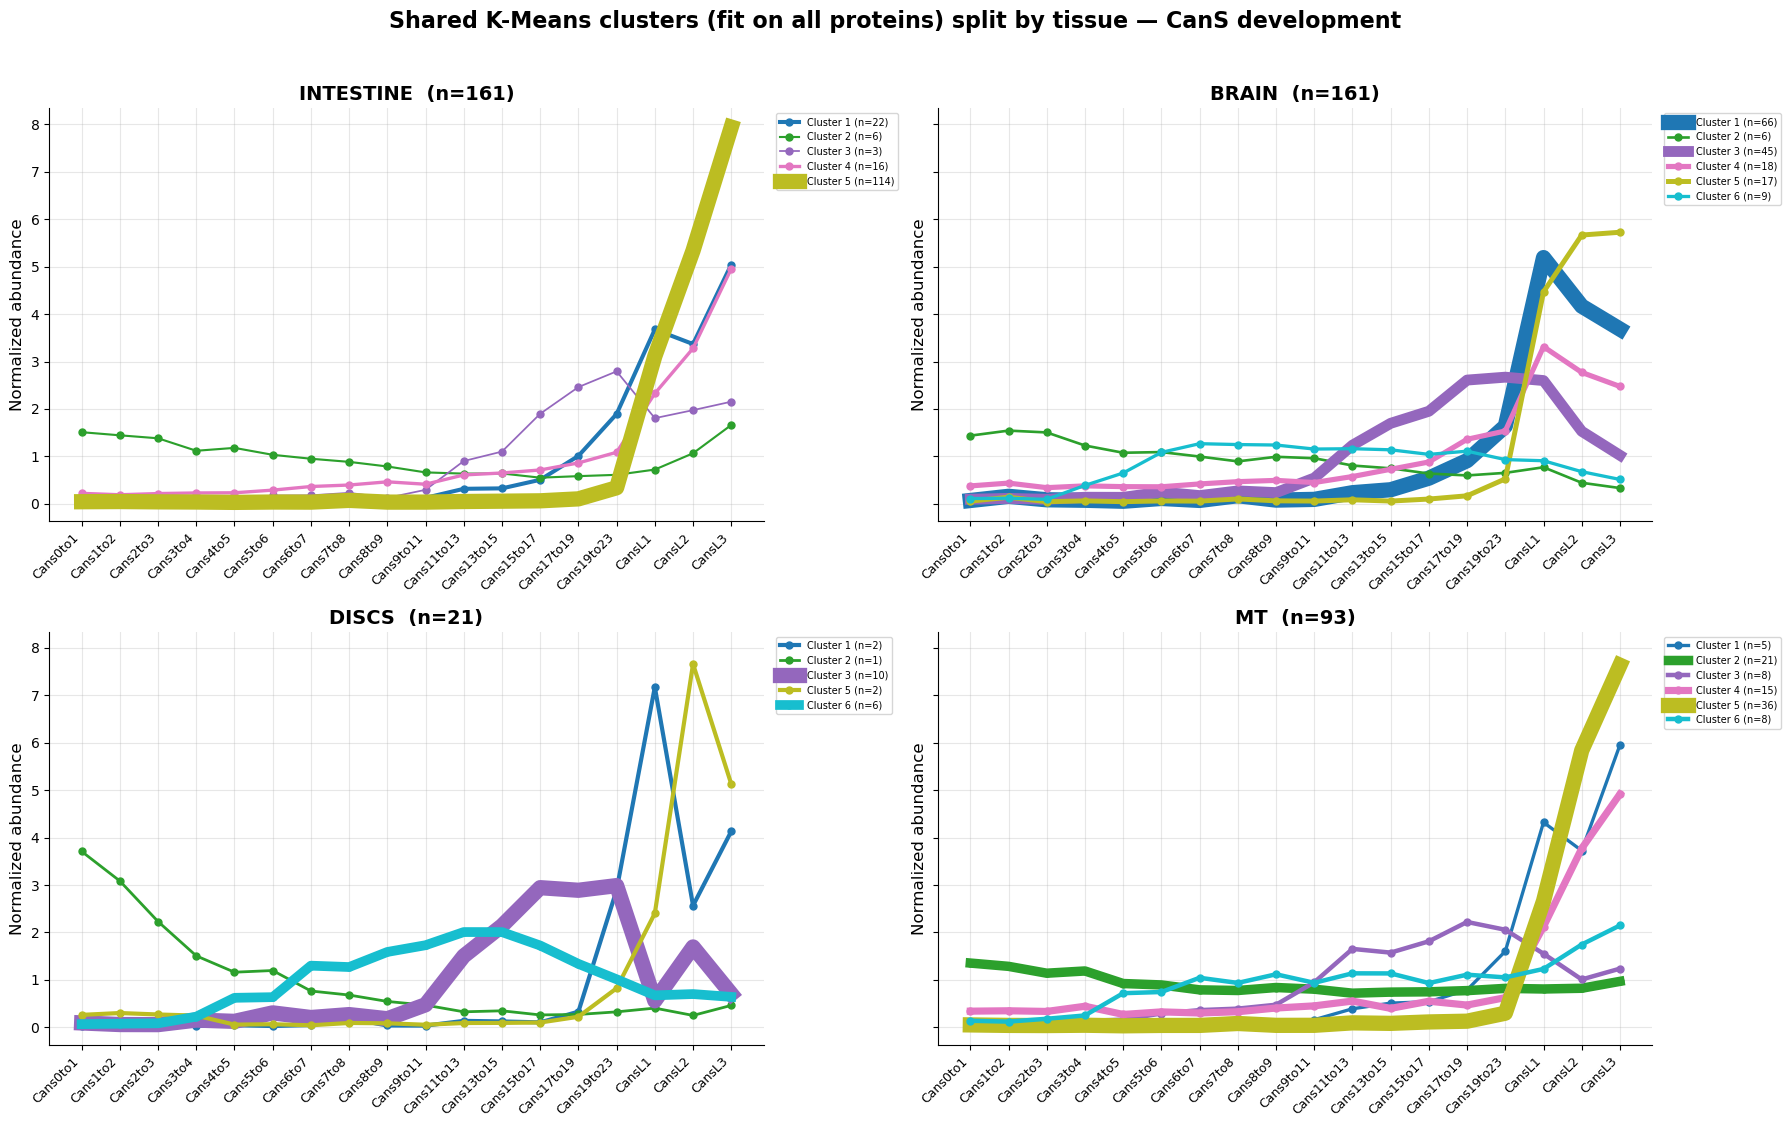

In [6]:
Xs = result_shared[channel_columns].dropna()
km_shared = KMeans(n_clusters=6, random_state=42, n_init=10)
result_shared.loc[Xs.index, 'dev_cluster'] = km_shared.fit_predict(StandardScaler().fit_transform(Xs)) + 1
result_shared['dev_cluster'] = result_shared['dev_cluster'].astype('Int64')
K_SHARED = int(result_shared['dev_cluster'].max())
cluster_cmap = plt.get_cmap('tab10', K_SHARED)
print(pd.crosstab(result_shared['dev_cluster'], result_shared['tissue']))


def plot_shared_clusters(ax, tissue, title, ylabel, xlabels, xfont, legend_kw, markersize):
    sub = result_shared[(result_shared['tissue'] == tissue) & result_shared['dev_cluster'].notna()]
    ns = [(sub['dev_cluster'] == c).sum() for c in range(1, K_SHARED + 1)]
    for c in range(1, K_SHARED + 1):
        members = sub.loc[sub['dev_cluster'] == c, channel_columns].dropna()
        if members.empty:
            continue
        ax.plot(experiment_channels, members.median(axis=0).values, color=cluster_cmap(c - 1),
                linewidth=1 + 10 * len(members) / max(ns), marker='o', markersize=markersize,
                label=f'Cluster {c} (n={len(members)})')
    ax.set_title(title.format(name=tissue.upper(), n=len(sub)), fontsize=14, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_xticks(range(len(experiment_channels)))
    ax.set_xticklabels(xlabels, rotation=45, ha='right', fontsize=xfont)
    ax.grid(True, alpha=0.3)
    ax.legend(**legend_kw)
    ax.spines[['top', 'right']].set_visible(False)


# Fig S5: all four tissues
TISSUE_ORDER = ['gut', 'brain', 'discs', 'mt']
fig, axes = plt.subplots(2, 2, figsize=(18, 11), squeeze=False, sharey=True)
for ax, t in zip(axes.flat, TISSUE_ORDER):
    plot_shared_clusters(ax, t, ('INTESTINE' if t == 'gut' else '{name}') + '  (n={n})', 'Normalized abundance',
                         experiment_channels, 9, dict(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=7), 5)
fig.suptitle('Shared K-Means clusters (fit on all proteins) split by tissue — CanS development',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
cm.save_fig(fig, OUT, 'figS5_shared_clusters_by_tissue')
plt.show()

## Fig 6D — brain-enriched proteins in the shared clusters

Saved fig6/fig6D_brain_clusters.pdf / .png


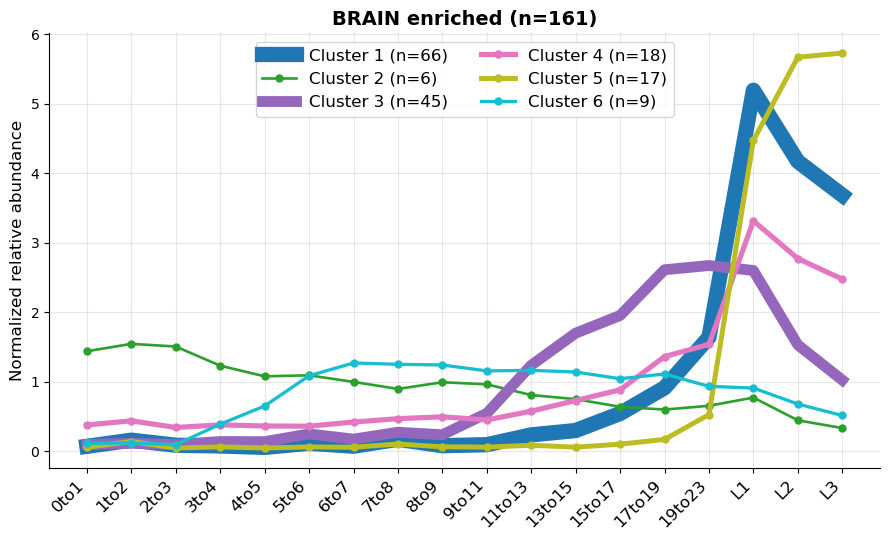

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))
plot_shared_clusters(ax, 'brain', '{name} enriched (n={n})', 'Normalized relative abundance',
                     [ch.replace('Cans', '') for ch in experiment_channels], 12,
                     dict(loc='upper center', fontsize=12, ncol=2), 5)
plt.tight_layout()
cm.save_fig(fig, OUT, 'fig6D_brain_clusters')
plt.show()

## Fig 6E — tissue-enriched proteins in MF time-course clusters
Clusters from Fig 3B (fate-specific 8, 9, 6 and the rising cluster 3). Bars = tissue-enriched proteins per tissue,
in the Fig 5 tissue colours (brain blue, discs purple, intestine red, MT green); n = all proteins in the cluster.

tissue   brain  discs  gut  mt  none  total
cluster                                    
8            0      1    2   0    32     35
9            2      0    0   0    31     33
6            1      3    2   6    79     91
3            6      1    2   3   993   1005


Saved fig6/fig6E_tissue_composition_mf_clusters.pdf / .png


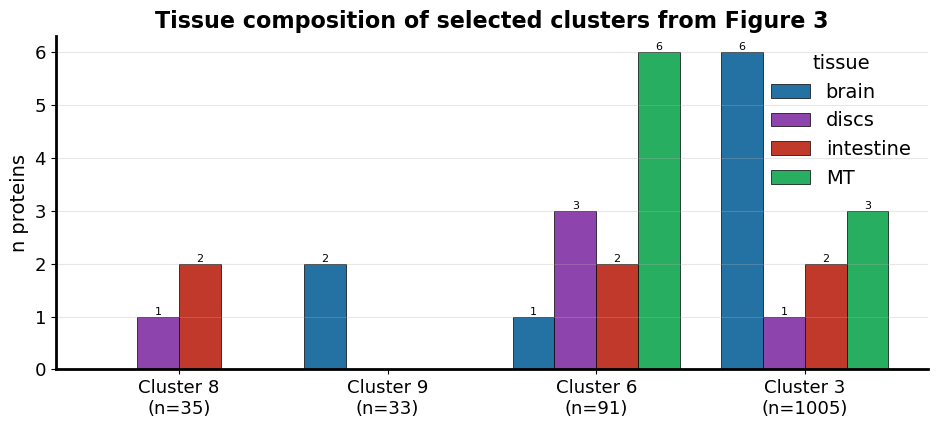

In [8]:
TISSUE_CLUSTERS = [8, 9, 6, 3]

mf = pd.read_csv(MF_CLUSTERS)
mf['tissue'] = mf['ProteinId'].map(tissue_excl.drop_duplicates('ProteinId').set_index('ProteinId')['tissue']).fillna('none')
TISSUES = [t for t in sorted(mf['tissue'].unique()) if t != 'none']
LEGEND_NAMES = {'gut': 'intestine', 'mt': 'MT'}                  # display only
tissue_colors = TISSUE_COLORS_DARK                                 # same colours as Fig 5

ct = (mf[mf['cluster'].isin(TISSUE_CLUSTERS)]
        .pivot_table(index='cluster', columns='tissue', values='ProteinId', aggfunc='count', fill_value=0)
        .reindex(index=TISSUE_CLUSTERS, columns=TISSUES + ['none'], fill_value=0))
ct['total'] = ct.sum(axis=1)
print(ct)

FIG3_STYLE = {'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,       # same style as the Fig 3 panels
              'xtick.labelsize': 13, 'ytick.labelsize': 13, 'axes.linewidth': 2.0}
with mpl.rc_context(FIG3_STYLE):
    x = np.arange(len(TISSUE_CLUSTERS))
    w = 0.8 / len(TISSUES)
    fig, ax = plt.subplots(figsize=(1.9 * len(TISSUE_CLUSTERS) + 2, 4.5))
    for i, t in enumerate(TISSUES):
        heights = ct[t].to_numpy(int)
        bars = ax.bar(x + (i - (len(TISSUES) - 1) / 2) * w, heights, w, color=tissue_colors[t],
                      edgecolor='black', linewidth=0.5, label=LEGEND_NAMES.get(t, t))
        for b, h in zip(bars, heights):
            if h:
                ax.text(b.get_x() + b.get_width() / 2, h, str(h), ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels([f'Cluster {c}\n(n={ct.at[c, "total"]})' for c in TISSUE_CLUSTERS])
    ax.set_ylabel('n proteins')
    ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
    ax.set_title('Tissue composition of selected clusters from Figure 3', fontweight='bold')
    ax.legend(title='tissue', frameon=False)
    ax.grid(True, axis='y', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    cm.save_fig(fig, OUT, 'fig6E_tissue_composition_mf_clusters')
    plt.show()

## Fig S4 — FlyBase gene groups across development
Each keyword matches every FlyBase group whose name contains it (case-insensitive); a gene in several matched groups is
counted once. Proteins with a complete profile only; one violin per time point.

Ribosome: 177 FBgn -> 164 proteins, 164 with complete profiles


Proteasome: 50 FBgn -> 35 proteins, 35 with complete profiles
CCT Chaperonin: 8 FBgn -> 8 proteins, 8 with complete profiles


Hsp70: 15 FBgn -> 11 proteins, 11 with complete profiles


E3s: 152 FBgn -> 110 proteins, 110 with complete profiles


tRNA Synthetases: 38 FBgn -> 38 proteins, 38 with complete profiles


Actins: 6 FBgn -> 3 proteins, 3 with complete profiles


Tubulins: 12 FBgn -> 10 proteins, 10 with complete profiles


Mito complexes: 122 FBgn -> 85 proteins, 85 with complete profiles


Transcription factors: 660 FBgn -> 405 proteins, 405 with complete profiles


Saved fig6/figS4_gene_group_violins.pdf / .png


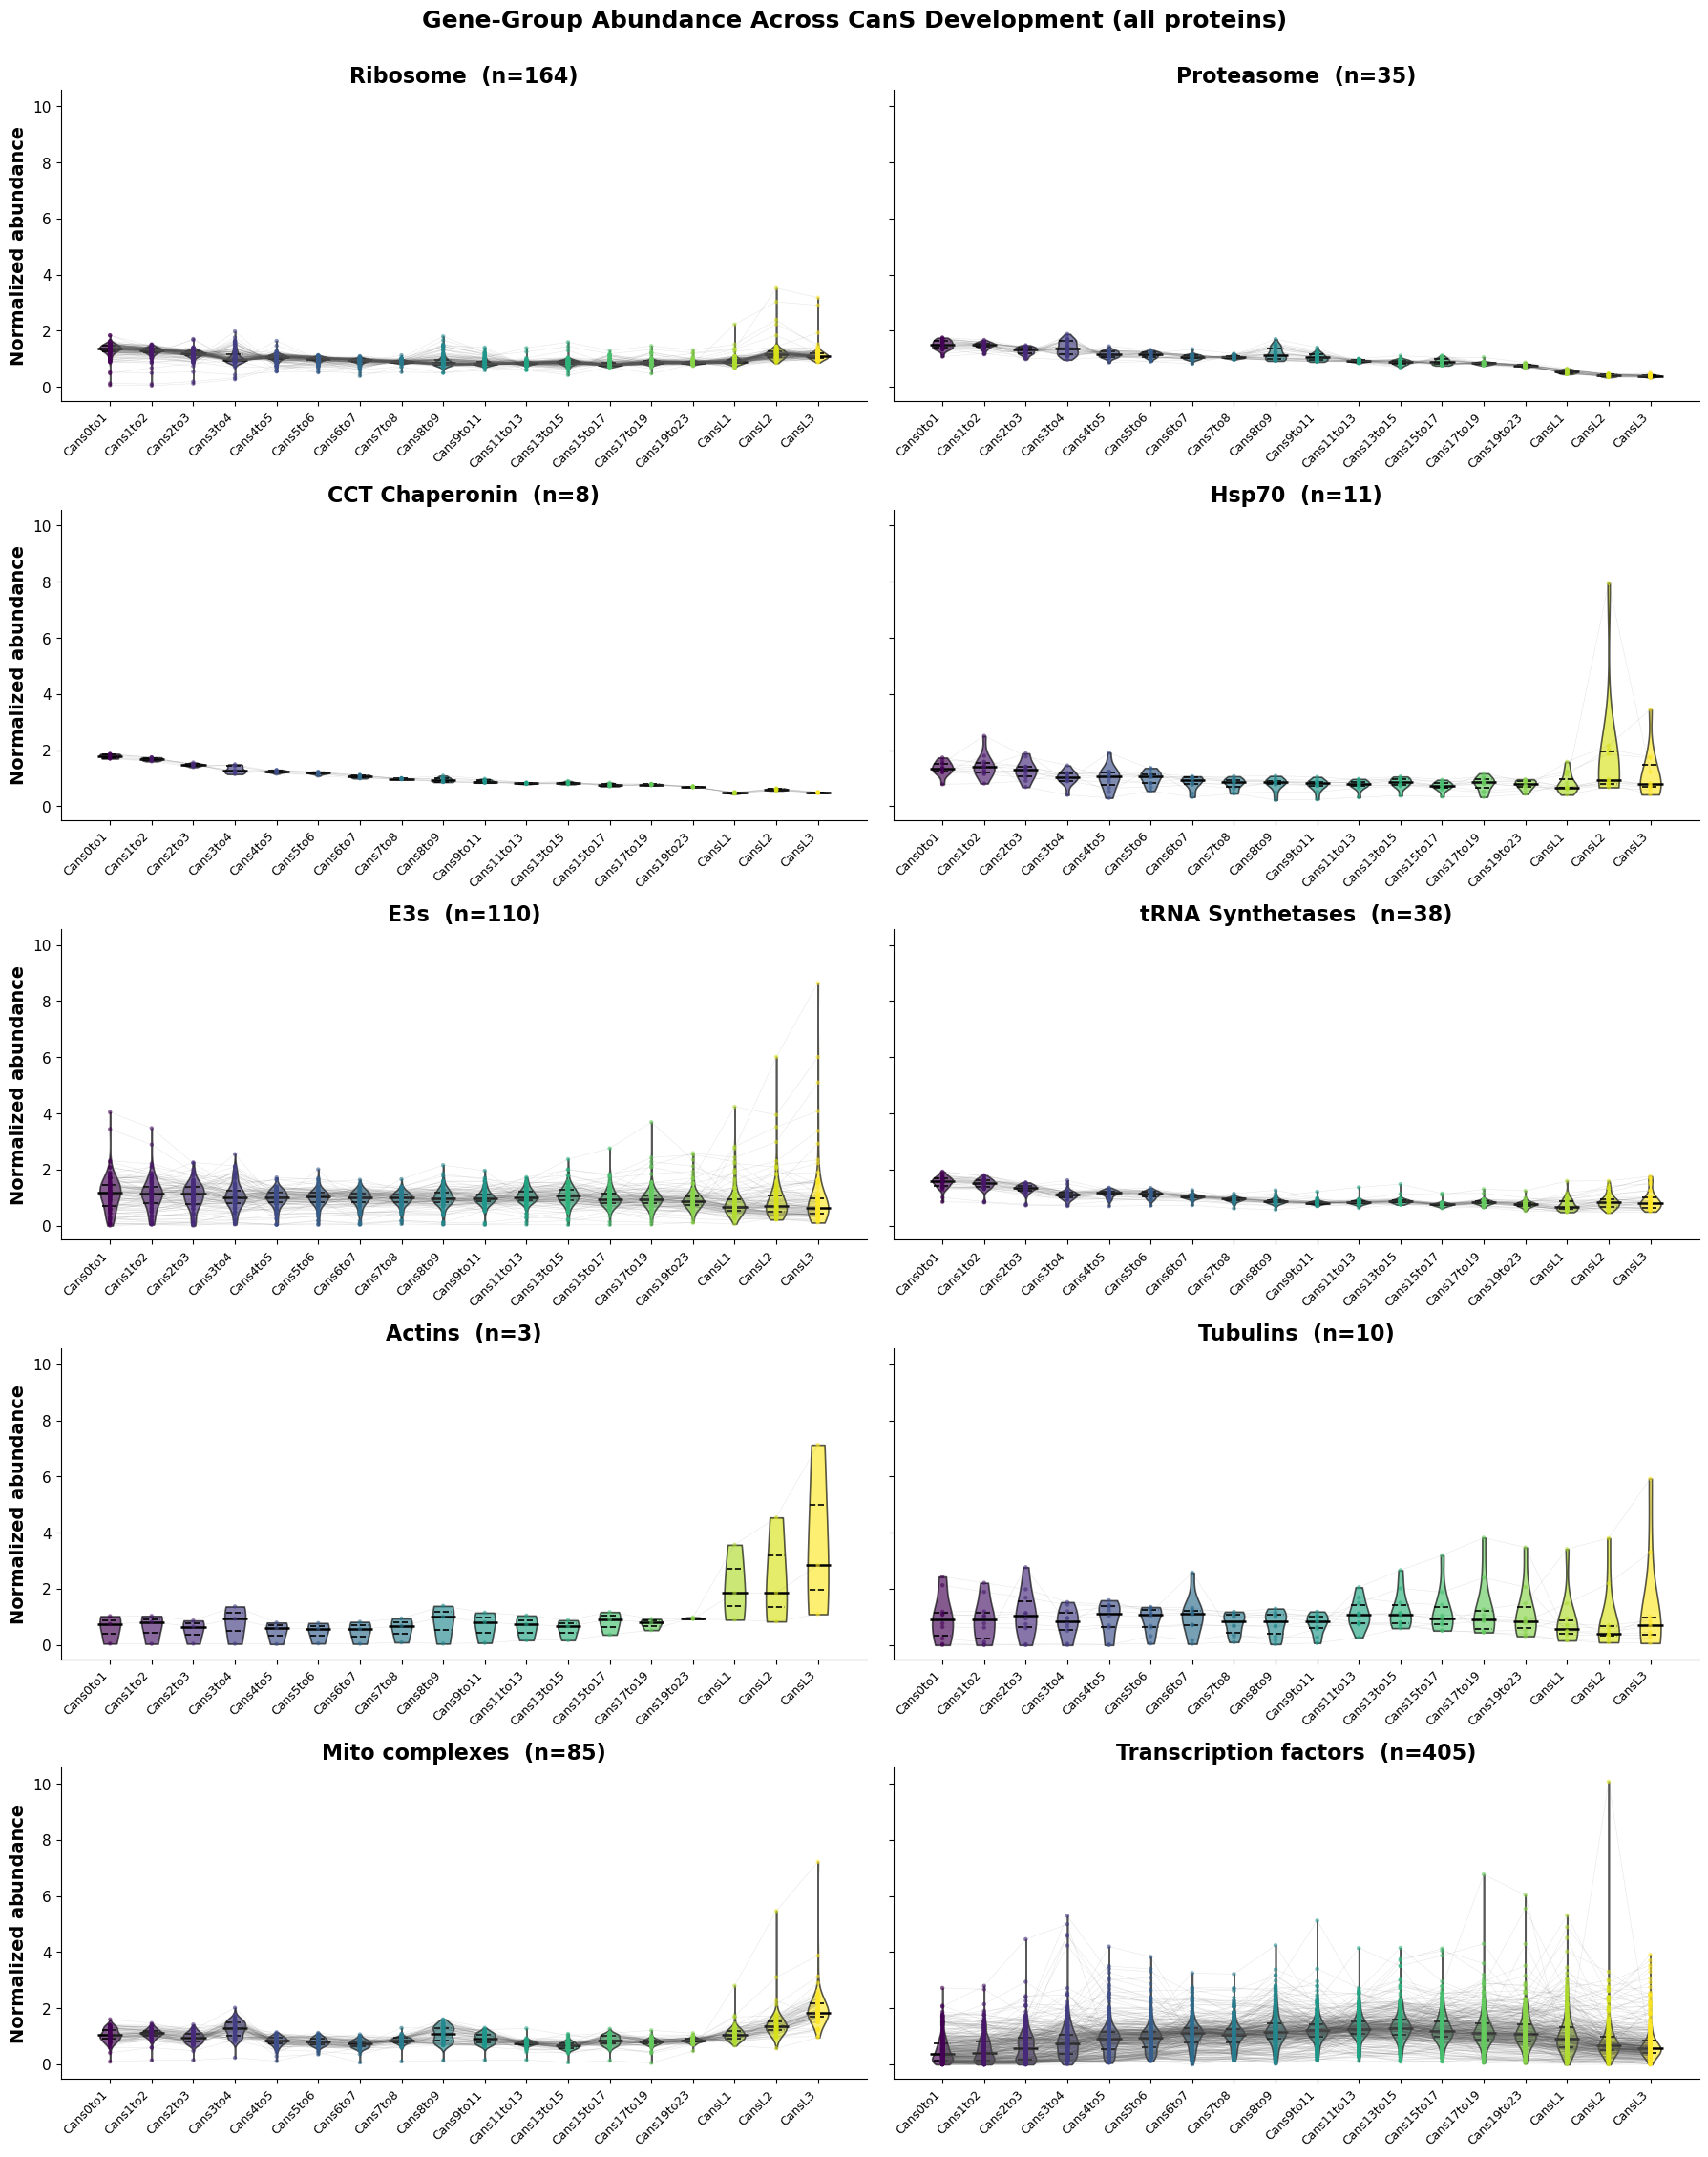

In [9]:
HK_PATTERNS = {                       # keyword in FB_group_name -> panel title
    'RIBOSOMAL SUBUNIT':         'Ribosome',
    'PROTEASOME':                'Proteasome',
    'CHAPERONIN CONTAINING TCP': 'CCT Chaperonin',
    'HEAT SHOCK PROTEIN 70':     'Hsp70',
    'UBIQUITIN LIGASES':         'E3s',
    'AMINOACYL-TRNA SYNTHETASE': 'tRNA Synthetases',
    'ACTINS':                    'Actins',
    'TUBULINS':                  'Tubulins',
    'MITOCHONDRIAL COMPLEX':     'Mito complexes',
    'TRANSCRIPTION FACTOR':      'Transcription factors',
}

gg = cm.read_gene_groups()
FBGN_COL = cm.detect_fbgn_col(result)
group_names = gg['FB_group_name'].dropna().unique()
group_to_label = {}
for pat, label in HK_PATTERNS.items():
    for g in sorted(g for g in group_names if re.search(pat, g, flags=re.IGNORECASE)):
        group_to_label.setdefault(g, label)          # first pattern wins on overlap
members = (gg.loc[gg['FB_group_name'].isin(group_to_label) & gg['Group_member_FB_gene_id'].notna(),
                  ['FB_group_name', 'Group_member_FB_gene_id']]
             .assign(Category=lambda d: d['FB_group_name'].map(group_to_label))
             .drop(columns='FB_group_name').drop_duplicates())

tp_colors = {tp: plt.get_cmap('viridis', len(experiment_channels))(i) for i, tp in enumerate(experiment_channels)}
positions = list(range(len(experiment_channels)))
fig, axes = plt.subplots(5, 2, figsize=(18, 22.5), sharey=True, squeeze=False)
for ax, label in zip(axes.flatten(), HK_PATTERNS.values()):
    fbgns = set(members.loc[members['Category'] == label, 'Group_member_FB_gene_id'])
    M = result.loc[result[FBGN_COL].isin(fbgns), channel_columns]
    Mv = M.values[M.notna().all(axis=1).values]
    n_pts = len(Mv)
    print(f'{label}: {len(fbgns)} FBgn -> {len(M)} proteins, {n_pts} with complete profiles')

    parts = ax.violinplot([Mv[:, k] for k in positions], positions=positions,
                          showmeans=False, showmedians=False, showextrema=False)
    for pc, tp in zip(parts['bodies'], experiment_channels):
        pc.set_facecolor(tp_colors[tp]); pc.set_edgecolor('black'); pc.set_linewidth(1.2); pc.set_alpha(0.65)
    for k in positions:
        q25, q50, q75 = np.percentile(Mv[:, k], [25, 50, 75])
        ax.hlines(q50, k - 0.30, k + 0.30, color='black', linewidth=1.8)
        ax.hlines([q25, q75], k - 0.20, k + 0.20, color='black', linewidth=1.2, linestyle='--')
    for j in range(n_pts):
        ax.plot(positions, Mv[j, :], color='#555555', linewidth=0.4, alpha=0.15, zorder=2)
    for k, tp in enumerate(experiment_channels):
        ax.scatter([k] * n_pts, Mv[:, k], s=10, color=tp_colors[tp], alpha=0.6, edgecolors='none', zorder=3)

    ax.set_title(f'{label}  (n={n_pts})', fontsize=16, fontweight='bold')
    ax.set_xticks(positions)
    ax.set_xticklabels(experiment_channels, fontsize=9, rotation=45, ha='right')
    ax.tick_params(axis='y', labelsize=11)
    ax.spines[['top', 'right']].set_visible(False)
for r in range(5):
    axes[r, 0].set_ylabel('Normalized abundance', fontsize=14, fontweight='bold')
fig.suptitle('Gene-Group Abundance Across CanS Development (all proteins)', fontsize=18, fontweight='bold', y=1.002)
fig.tight_layout()
cm.save_fig(fig, OUT, 'figS4_gene_group_violins')
plt.show()

## Supplementary Tables S7 and S8
- **S7** — every protein in the time course with its k-means cluster (Fig 6B) and, if tissue-enriched, its tissue
  (`gut` written as `intestine`).
- **S8** — the tissue-enriched proteins detected in the time course with their shared cluster (Fig 6D, Fig S5),
  `gut` written as `intestine`.

In [10]:
table_s7 = (result.merge(result_shared[['ProteinId', 'tissue']].drop_duplicates('ProteinId'), on='ProteinId', how='left')
                  .sort_values(['cluster', 'ProteinId']).reset_index(drop=True))
table_s7 = table_s7[['ProteinId', 'Number of peptides', 'sumSN', *channel_columns,
                     'gene_ID', 'gene_symbol', 'gene_fullname', 'polypeptide_symbol', 'cluster', 'tissue']]
table_s7['tissue'] = table_s7['tissue'].replace({'gut': 'intestine'})
cm.save_table(table_s7, 'Table_S7_CanS_timecourse')

table_s8 = (result_shared.assign(tissue=result_shared['tissue'].replace({'gut': 'intestine'}),
                                 tissue_cluster=result_shared['dev_cluster'])
            [['ProteinId', 'gene_symbol', 'tissue', 'Number of peptides', 'sumSN', *channel_columns,
              'gene_ID', 'gene_fullname', 'polypeptide_symbol', 'tissue_cluster']]
            .sort_values(['tissue', 'tissue_cluster', 'ProteinId']).reset_index(drop=True))
cm.save_table(table_s8, 'Table_S8_CanS_tissue_enriched')
print(table_s8['tissue'].value_counts().to_string())

Saved Table_S7_CanS_timecourse.csv  (8,061 rows x 27 columns)
Saved Table_S8_CanS_tissue_enriched.csv  (436 rows x 27 columns)
tissue
brain        161
intestine    161
mt            93
discs         21
